In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
plt.style.use("ggplot")
df = pd.read_csv("heart_disease_uci.csv")
display(df.head())
print("Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
display(df.describe())

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,29,0,2,114.999361,236.412170,0,0,169.909806,0,0.418406,0,3.0,2,2
1,67,0,3,101.387785,320.890252,0,0,169.422780,0,-0.551019,0,2.0,1,3
2,61,1,3,92.686298,NaN,0,1,150.560444,0,1.453019,2,0.0,3,0
3,49,1,1,109.887086,240.515045,0,2,145.655477,1,0.550030,2,NaN,1,1
4,48,1,3,121.743845,251.195429,0,2,145.811823,1,-0.075736,0,0.0,0,3


Shape: (320, 14)

Missing Values:
age          0
sex          0
cp           0
trestbps    12
chol        12
fbs          0
restecg      0
thalch       0
exang        0
oldpeak     12
slope        0
ca          12
thal         0
num          0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       320 non-null    int64  
 1   sex       320 non-null    int64  
 2   cp        320 non-null    int64  
 3   trestbps  308 non-null    float64
 4   chol      308 non-null    float64
 5   fbs       320 non-null    int64  
 6   restecg   320 non-null    int64  
 7   thalch    320 non-null    float64
 8   exang     320 non-null    int64  
 9   oldpeak   308 non-null    float64
 10  slope     320 non-null    int64  
 11  ca        308 non-null    float64
 12  thal      320 non-null    int64  
 13  num       320 non-null    

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
count,320.000000,320.000000,320.000000,308.000000,308.000000,320.000000,320.000000,320.000000,320.000000,308.000000,320.000000,308.000000,320.000000,320.00000
mean,51.925000,0.493750,1.540625,128.351012,240.767633,0.434375,1.021875,147.596484,0.512500,0.932594,0.953125,1.561688,1.540625,1.94375
std,14.995736,0.500744,1.143980,18.422554,43.419965,0.496451,0.824482,20.468760,0.500627,0.969005,0.845969,1.126853,1.107784,1.34256
min,25.000000,0.000000,0.000000,76.638481,75.821423,0.000000,0.000000,90.887624,0.000000,-2.047633,0.000000,0.000000,0.000000,0.00000
25%,40.000000,0.000000,0.000000,115.089322,214.901722,0.000000,0.000000,135.422957,0.000000,0.254064,0.000000,1.000000,1.000000,1.00000
50%,52.000000,0.000000,2.000000,128.752054,241.679424,0.000000,1.000000,147.923798,1.000000,1.001938,1.000000,2.000000,2.000000,2.00000
75%,64.250000,1.000000,3.000000,140.483157,266.828722,1.000000,2.000000,160.663425,1.000000,1.549702,2.000000,3.000000,3.000000,3.00000
max,79.000000,1.000000,3.000000,175.887903,383.048416,1.000000,2.000000,208.284893,1.000000,3.857438,2.000000,3.000000,3.000000,4.00000


In [3]:
df = df[df["num"].notna()].copy()
df["num"] = (df["num"] > 0).astype(int)
df = df.select_dtypes(include=["int64", "float64"])
X = df.drop("num", axis=1)
y = df["num"]
feature_names = X.columns
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (320, 13)
Target shape: (320,)


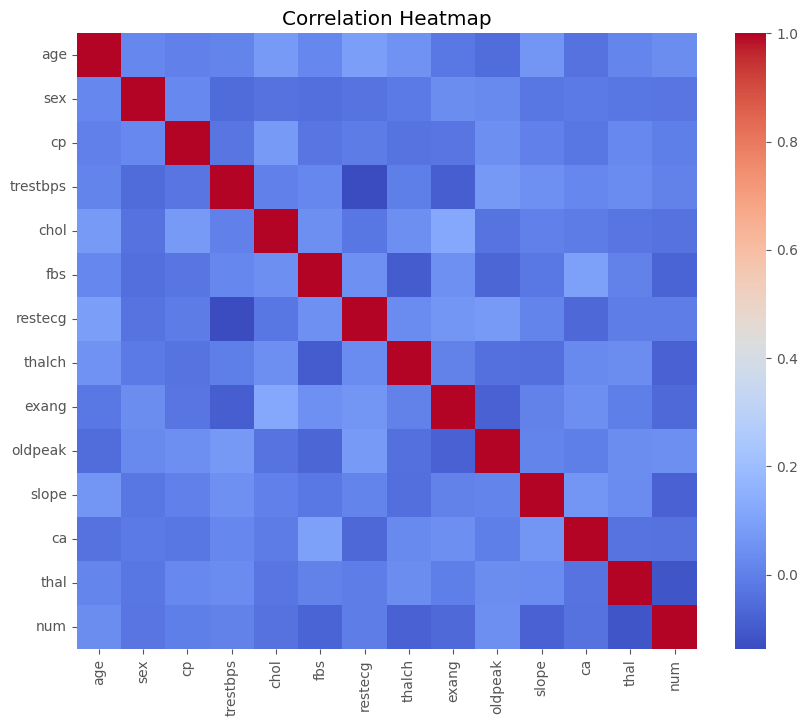

In [4]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap")
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 256
Testing samples: 64


In [6]:
imputer = SimpleImputer(strategy="mean")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)
print("Shape after preprocessing:", X_train.shape)

Shape after preprocessing: (256, 13)


In [7]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training and testing features standardized.")

Training and testing features standardized.


In [8]:
ridge = LogisticRegression(penalty="l2", solver="liblinear", C=0.1, random_state=42)
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)
ridge_accuracy = accuracy_score(y_test, ridge_pred)
print("Ridge Accuracy:", round(ridge_accuracy, 4))

Ridge Accuracy: 0.8281


/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


In [9]:
lasso = LogisticRegression(penalty="l1", solver="liblinear", C=0.05, random_state=42)
lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)
lasso_accuracy = accuracy_score(y_test, lasso_pred)
print("Lasso Accuracy:", round(lasso_accuracy, 4))

Lasso Accuracy: 0.8281


/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,Model,Accuracy
0,Ridge,0.828125
1,Lasso,0.828125


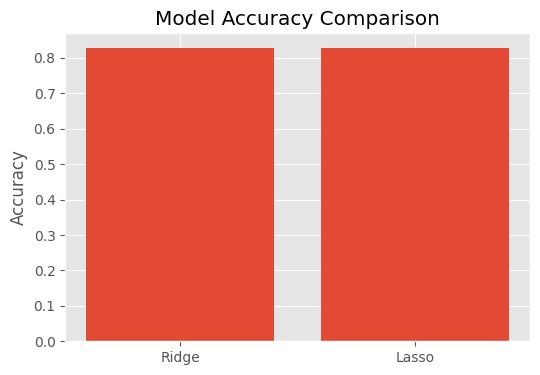

In [10]:
results = pd.DataFrame({
    "Model": ["Ridge", "Lasso"],
    "Accuracy": [ridge_accuracy, lasso_accuracy]
})
display(results)
plt.figure(figsize=(6, 4))
plt.bar(results["Model"], results["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.show()

In [11]:
print("Ridge Confusion Matrix")
print(confusion_matrix(y_test, ridge_pred))
print(classification_report(y_test, ridge_pred, zero_division=0))
print("Lasso Confusion Matrix")
print(confusion_matrix(y_test, lasso_pred))
print(classification_report(y_test, lasso_pred, zero_division=0))

Ridge Confusion Matrix
[[ 0 11]
 [ 0 53]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        11
           1       0.83      1.00      0.91        53

    accuracy                           0.83        64
   macro avg       0.41      0.50      0.45        64
weighted avg       0.69      0.83      0.75        64

Lasso Confusion Matrix
[[ 0 11]
 [ 0 53]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        11
           1       0.83      1.00      0.91        53

    accuracy                           0.83        64
   macro avg       0.41      0.50      0.45        64
weighted avg       0.69      0.83      0.75        64



,Feature,Ridge,Lasso
0,age,0.050,0.0
1,sex,-0.082,0.0
2,cp,0.113,0.0
3,trestbps,0.033,0.0
4,chol,-0.041,0.0
5,fbs,-0.152,0.0
6,restecg,-0.020,0.0
7,thalch,-0.123,0.0
8,exang,-0.122,0.0
9,oldpeak,0.088,0.0


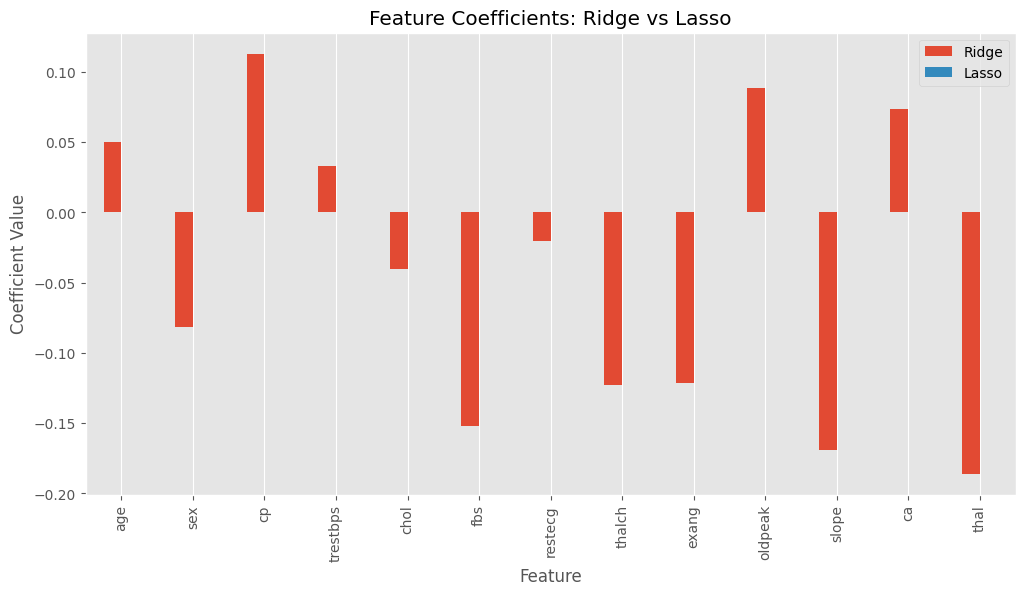

In [12]:
coef = pd.DataFrame({
    "Feature": feature_names,
    "Ridge": ridge.coef_[0],
    "Lasso": lasso.coef_[0]
})
display(coef.round(3))
coef.set_index("Feature").plot(kind="bar", figsize=(12, 6))
plt.title("Feature Coefficients: Ridge vs Lasso")
plt.ylabel("Coefficient Value")
plt.grid(axis="y")
plt.show()

In [13]:
ridge_features = np.sum(ridge.coef_[0] != 0)
lasso_features = np.sum(lasso.coef_[0] != 0)
print("Number of Features Used")
print("Ridge:", ridge_features)
print("Lasso:", lasso_features)

Number of Features Used
Ridge: 13
Lasso: 0
